# 03. Forced photometry on Spitzer/IRAC

The IRAC point response function (PRF) is 1.7 to 2.0 arcsec wide, so
neighbouring Euclid sources often blend. As for unWISE in
[notebook 02](02_wise_forced_photometry.ipynb), the VIS source models of
[notebook 01](01_nisp_forced_photometry.ipynb) are held fixed,
convolved with the IRAC PRF, and their fluxes are fitted together with the
background. The PRF varies across the detector, and each mosaic pixel
combines exposures taken at different detector positions and orientations,
so an effective PRF is rebuilt for each field; section 3 shows how.

The field is a 200 arcsec region of EDF-F. IRAC1 to IRAC4 are channels 1
to 4, at 3.6, 4.5, 5.8 and 8.0 µm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import euclid_phot as ep
from euclid_phot.config import DEFAULT_DATA_DIR
from astropy.table import Table
from euclid_phot import forced, irac
from euclid_phot.background import estimate_sep_background
from euclid_phot.sources import clone_sources
from euclid_phot.tractor_image import make_tractor_image
from euclid_phot.units import UJY_PER_NMGY, pixel_scale_arcsec

DATA_DIR = DEFAULT_DATA_DIR  # download cache; set EUCLID_PHOT_DATA_DIR to move it
IRAC_DIR = DATA_DIR / "irac"
TARGET_RA, TARGET_DEC = 52.932, -28.088
SIZE_ARCSEC = 200.0  # memory and run time: README, "Computing cost"
CHANNELS = ("IRAC1", "IRAC2", "IRAC3", "IRAC4")
WISE_BANDS = ("W1", "W2")
MOSAIC_BACKEND = "dawn"
DAWN_FIELD = "EDFF"
N_WORKERS = 10

## 1. Input images

`MOSAIC_BACKEND` selects the IRAC images:

- `"dawn"`: the deep [Cosmic Dawn Survey](https://irsa.ipac.caltech.edu/data/SPITZER/Cosmic_Dawn/)
  mosaics, available only in the survey fields.
- `"seip"`: the [SEIP Super Mosaics](https://irsa.ipac.caltech.edu/data/SPITZER/Enhanced/SEIP/),
  with wider archive coverage.
- `"pbcd"`: Level 2 mosaics of single observations from the
  [Spitzer Heritage Archive](https://irsa.ipac.caltech.edu/docs/knowledgebase/spitzer_sha.html),
  for fields outside the other two.

The observed images confirm the position and coverage before the fit.

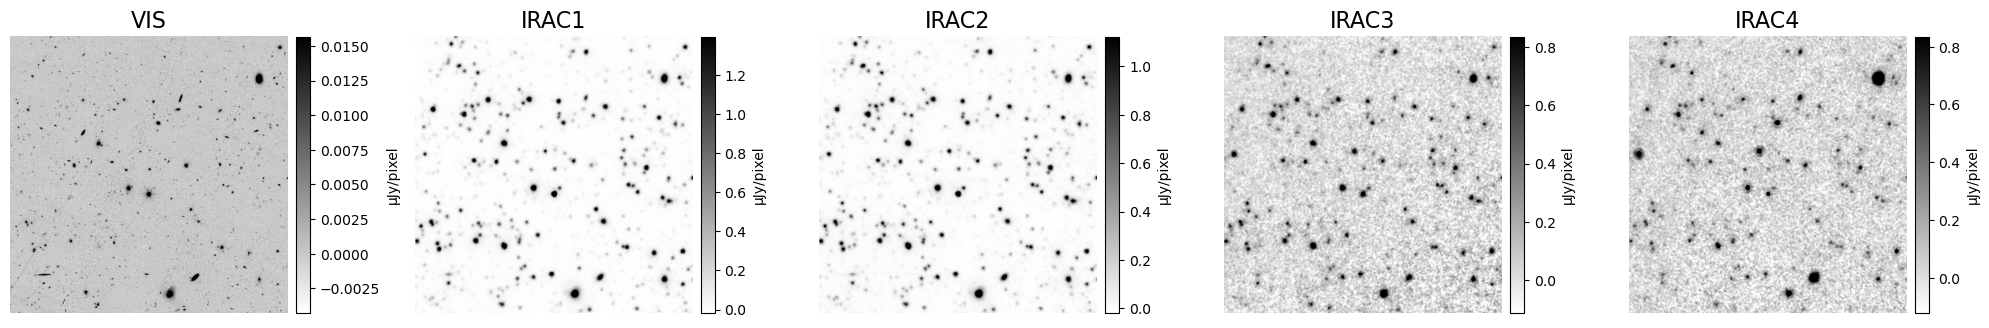

In [2]:
vis = ep.fetch_cutout("VIS", TARGET_RA, TARGET_DEC, SIZE_ARCSEC,)
images = {"VIS": vis.data * ep.viz.ujy_per_unit(vis)}
for channel in CHANNELS:
    mosaic = irac.fetch_irac_mosaic(TARGET_RA, TARGET_DEC, channel,
                                    size_arcsec=SIZE_ARCSEC,
                                    mosaic_backend=MOSAIC_BACKEND,
                                    data_root=IRAC_DIR)
    images[channel] = mosaic.cutout.data_ujy
ep.viz.show_images(images, units={band: "µJy/pixel" for band in images})
plt.show()

*The observed images of the field: VIS and the IRAC channels, each on its own scale.*

## 2. VIS models and IRAC fit

One call to `run_forced_photometry` fits the VIS models with the
model-selection tree, as in notebook 01, and then fits them to unWISE and
IRAC. For each IRAC channel it builds the effective PRF, subtracts a SEP
background and fits the fluxes; each centroid may move by up to one
native IRAC pixel, about 1.2 arcsec. `irac_options` selects the mosaics.
Section 3 repeats the IRAC1 fit step by step.

Pixel weights come from the mosaic uncertainty map. The statistical errors
are scaled up when the residuals are noisier than the map predicts.
`flux_err_<band>_ujy` adds a 2% PRF systematic in quadrature (section 8);
`result.irac_results[band]["flux_err_stat_ujy"]` leaves it out.

In [3]:
result = ep.run_forced_photometry(
    TARGET_RA, TARGET_DEC, SIZE_ARCSEC,
    prior={"band": "VIS", "objects": "mer", "model_selection": "tree"},
    target_bands={"euclid": (), "wise": WISE_BANDS, "irac": CHANNELS},
    irac_options={"mosaic_backend": MOSAIC_BACKEND},
    psf_product="grid", persource_psf=True, mask_bright_stars=True,
    calibrate_errors=False, data_dir=DATA_DIR, n_workers=N_WORKERS,
)
catalog = result.to_table()
print(f"\n{len(catalog)} VIS sources")

[1/7] MER catalog from cache (mer_catalog_52.9320_-28.0880_200.fits)
[2/7] discover mosaics for VIS (lazy; only on a cache miss)
[3/7] fetch cutouts: VIS
[4/7] build per-band PSFs (GRID-PSF, radius=150")
[5/7] build Tractor image + source models on VIS
[5a] STARSIGNAL bright-star mask: 13178 pixels (0.33%) excluded from the VIS fit


[6/7] VIS fit (free, forced-photometry)


[+] WISE forced phot: W1, W2


[+] IRAC forced phot: IRAC1, IRAC2, IRAC3, IRAC4
  IRAC1: mosaic and effective PRF (dawn)


  IRAC1: 856 sources fitted, chi inflation 1.80
  IRAC2: mosaic and effective PRF (dawn)


  IRAC2: 856 sources fitted, chi inflation 1.18
  IRAC3: mosaic and effective PRF (dawn)


  IRAC3: 856 sources fitted, chi inflation 1.00
  IRAC4: mosaic and effective PRF (dawn)


  IRAC4: 856 sources fitted, chi inflation 1.00

856 VIS sources


## 3. The IRAC fit, step by step

Every band in this package runs the same core recipe, and each adds what
its data need. Here it is for IRAC1, where the additions are a background
map, a PRF that changes across the mosaic, and a bounded shift of each
centroid.

1. **IRAC inputs.** The mosaic cutout in µJy/pixel, its uncertainty map,
   and the effective PRF come from `irac.prepare_channel`. The PRF is a
   grid of stamps rebuilt from the detector PRFs of the
   [IRAC Instrument Handbook](https://irsa.ipac.caltech.edu/data/SPITZER/docs/irac/iracinstrumenthandbook/19/#_Toc82083619)
   and the exposures contributing to the mosaic, following
   [PRFMAP](https://github.com/cosmic-dawn/prfmap); the nearest stamp
   renders each source. The run above has already cached it.
2. **Tractor image.** A SEP background map is subtracted first, so the
   fluxes cannot absorb a varying sky. The pixels, inverse variance,
   effective PRF, WCS and photometric scale are then combined by
   `make_tractor_image`; one AB nanomaggy is 3.631 µJy.
3. **Source models.** The VIS sources within 15 arcsec of the cutout and
   covered by an exposure are kept by `irac.select_irac_scene`, and their
   models are copied into IRAC1 by `clone_sources`, with a render patch that
   does not crop the PRF wings.
4. **Solve.** Everything but the fluxes is frozen with `forced.flux_tractor`
   and the fluxes are solved by `forced.solve_fluxes`. Fluxes and centroids
   are then allowed to move together by `forced.fit_bounded_positions`, each
   centroid within one native pixel of its VIS position, and the fluxes are
   solved again there; the `"constrained"` optimizer enforces that bound.
5. **Errors.** Each flux's inverse variance becomes a 1σ error, scaled by
   the robust scatter of (data − model)/σ through `forced.chi_inflation`.
   The Handbook PRF flux correction and the 2% PRF systematic are then
   applied by `irac.irac_catalog`.

In [4]:
channel = "IRAC1"

# 1. IRAC's own inputs: the mosaic cutout and its effective PRF
prepared = irac.prepare_channel(TARGET_RA, TARGET_DEC, channel, size_arcsec=SIZE_ARCSEC,
                                mosaic_backend=MOSAIC_BACKEND, data_dir=IRAC_DIR)
cutout, builder = prepared.cutout, prepared.prf_builder
scale = pixel_scale_arcsec(cutout.wcs)

# 2. The Tractor image: background-subtracted µJy pixels and the effective PRF
background = estimate_sep_background(cutout.data_ujy, cutout.fit_mask, scale)
science = cutout.data_ujy.astype(np.float32)
data = np.where(np.isfinite(science), science - background.image, 0).astype(np.float32)
tim = make_tractor_image(data, cutout.invvar.astype(np.float32),
                         cutout.wcs, prepared.tractor_psf, band=channel,
                         nmgy_to_data=UJY_PER_NMGY)

# 3. The VIS models of the sources on the mosaic, cloned into IRAC1
scene = Table({"object_id": np.arange(len(result.sources)),
               "ra": [s.pos.ra for s in result.sources],
               "dec": [s.pos.dec for s in result.sources]})
scene, on_mosaic = irac.select_irac_scene(scene, result.sources, cutout, builder)
sources = clone_sources(on_mosaic, channel, psf_halfsize_pix=builder.stamp_size // 2,
                        pixel_scale_arcsec=scale)
prior_ra = np.array([s.pos.ra for s in sources])
prior_dec = np.array([s.pos.dec for s in sources])

# 4. Fluxes; fluxes and centroids within one native pixel; fluxes again
max_shift = irac.IRAC_NATIVE_PIXEL_SCALE_ARCSEC[channel]
tractor = forced.flux_tractor(tim, sources, optimizer="constrained")
forced.solve_fluxes(tractor)
forced.fit_bounded_positions(tractor, sources, prior_ra, prior_dec,
                             max_shift_arcsec=max_shift, pixel_scale_arcsec=scale)
solved = forced.solve_fluxes(tractor)

# 5. Errors scaled by the residual scatter; PRF correction and 2% systematic
inflation, pool, n_pool = forced.chi_inflation(tim.getImage(), tractor.getModelImage(0),
                                               tim.getInvvar())
err_stat = forced.flux_errors_ujy(
    forced.flux_inverse_variance(solved, tractor, len(sources)), inflation)
step = irac.irac_catalog(scene, sources, channel, err_stat, builder,
                         prior_ra, prior_dec, max_shift, scale)
shift = np.asarray(step["position_shift_arcsec"])
moved = shift > 0.01
print(f"{len(sources)} sources on the mosaic; chi inflation {inflation:.2f}; "
      f"{moved.sum()} centroids moved by more than 0.01 arcsec "
      f"(median {np.median(shift[moved]) if moved.any() else 0:.2f}, "
      f"{np.count_nonzero(step['position_at_limit'])} at the {max_shift:.2f} arcsec limit)")
rows = np.asarray(step["object_id"])
diff = (np.asarray(step["flux_irac1_ujy"]) - result.irac_results[channel]["flux_ujy"][rows]) \
    / np.asarray(step["fluxerr_irac1_ujy"])
print(f"Largest difference from run_forced_photometry: {np.nanmax(np.abs(diff)):.1e} sigma")

856 sources on the mosaic; chi inflation 1.80; 112 centroids moved by more than 0.01 arcsec (median 0.02, 2 at the 1.22 arcsec limit)
Largest difference from run_forced_photometry: 0.0e+00 sigma


## 4. Data, model, and residuals

The central 100 arcsec. Data and model share one brightness scale per band,
and the residual uses the same scale. Circles mark the VIS sources.

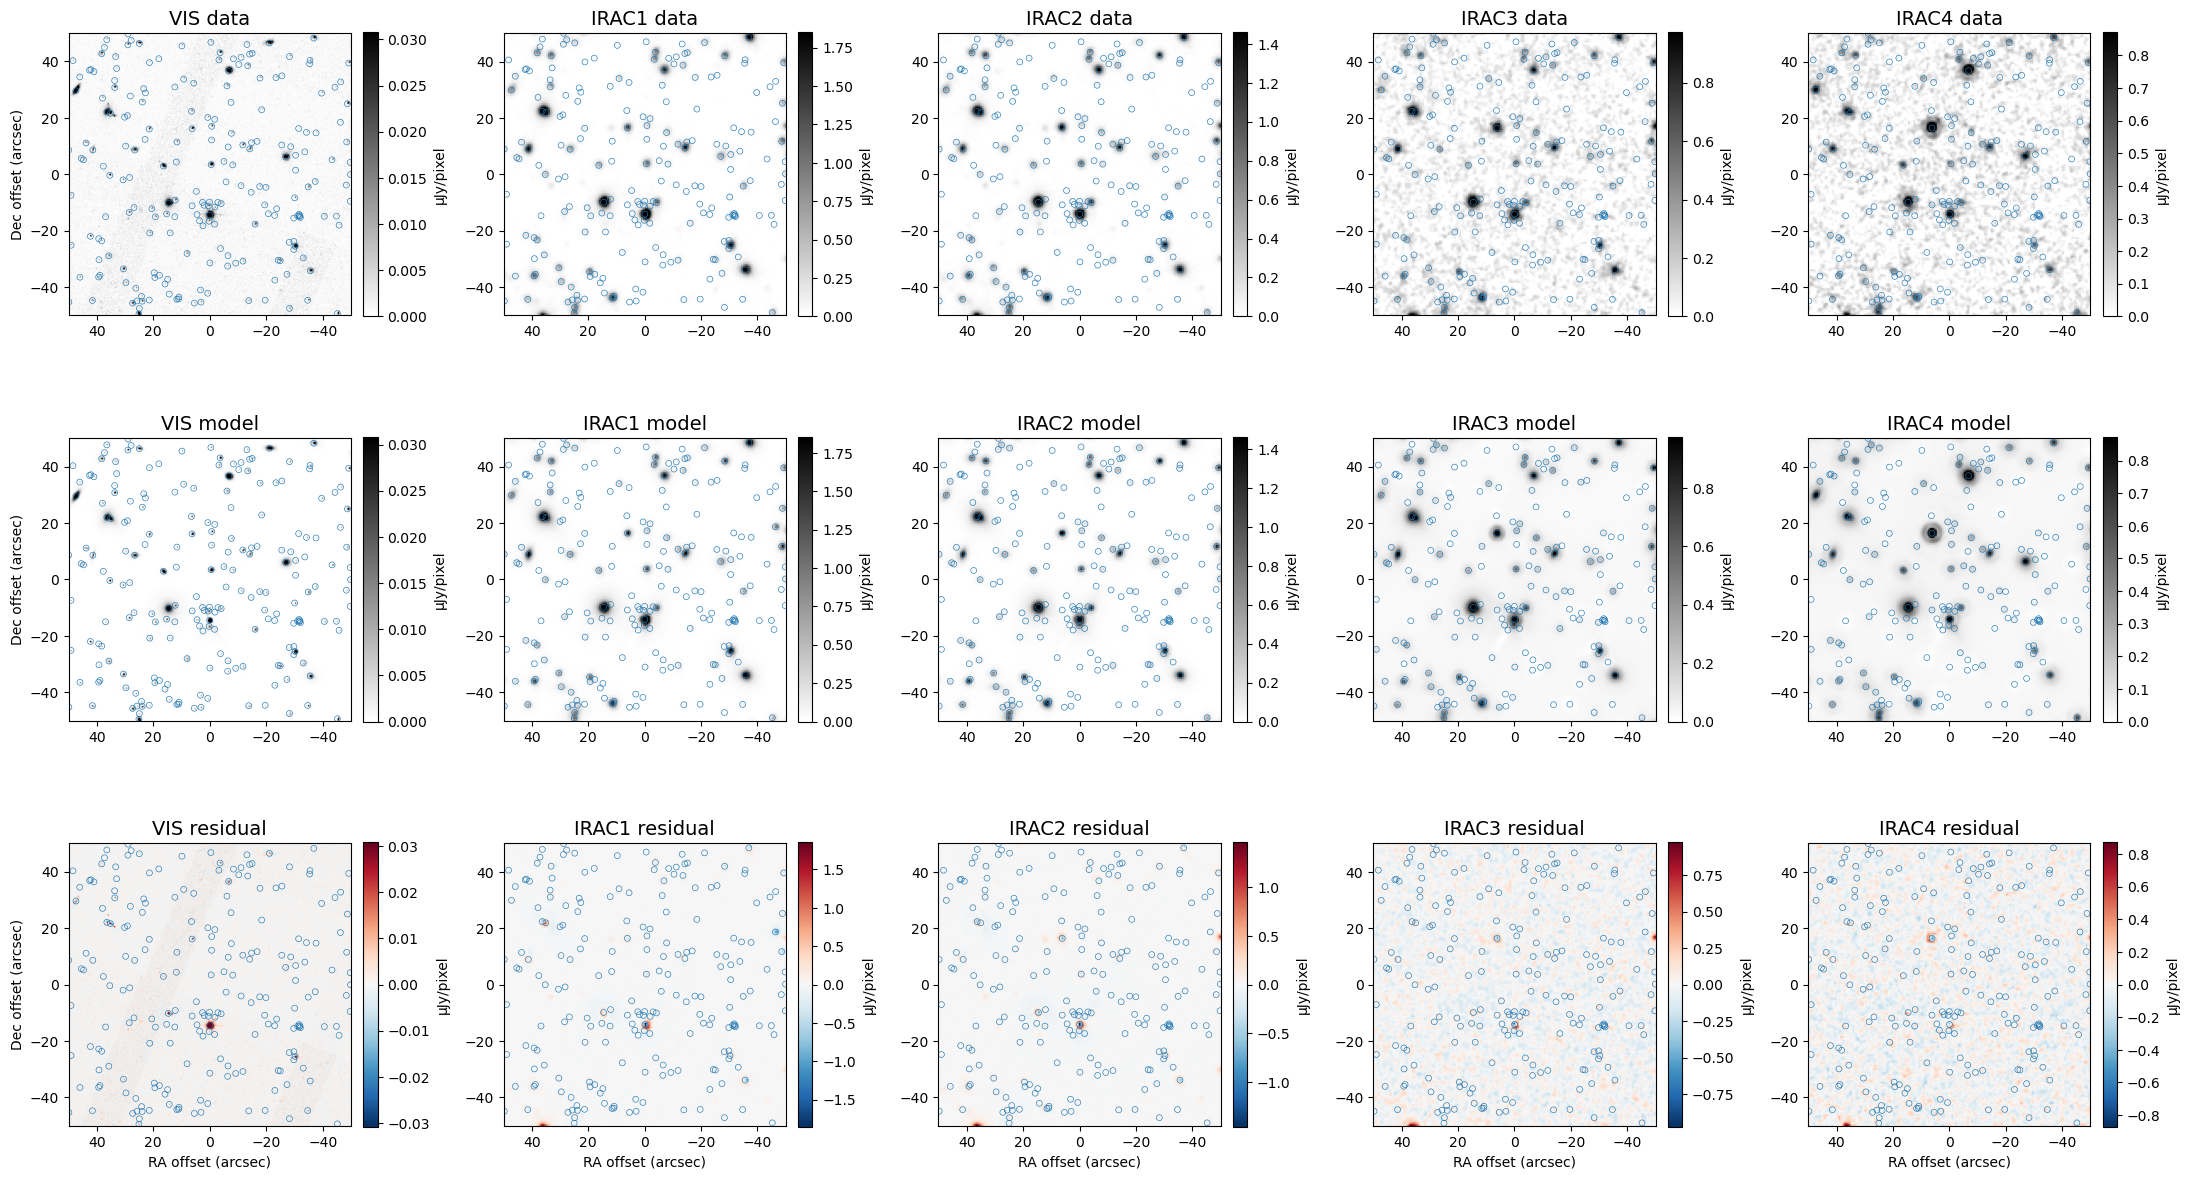

In [5]:
ep.viz.show_fit(result, ("VIS", *CHANNELS), size_arcsec=100.0)
plt.show()

*The central 100 arcsec in VIS and each IRAC channel: data, model, and residual, with circles at
the VIS sources.*

## 5. Catalog

`to_table` gives one row per VIS source with the same columns as the
other notebooks: flux, error, AB magnitude and its error in every band,
in microJansky, plus the model class and the `reliable` flag.

In [6]:
cols = ["object_id", "ra", "dec", "model", "reliable"]
for band in CHANNELS:
    cols += [f"flux_{band}_ujy", f"flux_err_{band}_ujy"]
catalog.write("irac_photometry.csv", overwrite=True)
print(f"wrote {len(catalog)} sources x {len(catalog.colnames)} columns to irac_photometry.csv")
catalog[cols][:8]

wrote 856 sources x 59 columns to irac_photometry.csv


object_id,ra,dec,model,reliable,flux_IRAC1_ujy,flux_err_IRAC1_ujy,flux_IRAC2_ujy,flux_err_IRAC2_ujy,flux_IRAC3_ujy,flux_err_IRAC3_ujy,flux_IRAC4_ujy,flux_err_IRAC4_ujy
,deg,deg,,,uJy,uJy,uJy,uJy,uJy,uJy,uJy,uJy
int64,float64,float64,str20,bool,float64,float64,float64,float64,float64,float64,float64,float64
-529320082280920152,52.93200822,-28.09201521,PointSource,False,126.466528169006,2.531147328931879,72.86914133483428,1.4587169022283426,43.28176294134605,0.9745426661015174,25.40794300246452,0.7288027072927432
-529154648281026546,52.91546485,-28.10265462,PointSource,False,33.92854056782397,0.6856376207694679,19.971508648087802,0.40596104936776317,14.47918066965637,0.5551512403268516,7.736419660302548,0.5542821780079009
-529224813280950777,52.92248131,-28.09507777,PointSource,False,39.12228346634753,0.7863127319605656,19.839455430192917,0.4008954817534377,13.96649469391384,0.4973069316393464,7.2885151319052826,0.5364197577888092
-529579574281031082,52.95795745,-28.10310824,PointSource,False,41.048655404416515,0.8228912950731585,22.097137051749915,0.444105511202759,16.470038239302745,0.4899786972907023,7.221753176413668,0.4888948500004441
-529272473281119379,52.92724731,-28.11193794,SersicGalaxy,False,339.90350718531204,6.801216717600791,272.5391736436779,5.45255855222639,156.19583443602176,3.222304976500129,93.63141633472537,2.0976699993534025
-529554580281022487,52.95545808,-28.10224875,PointSource,False,13.045872589640487,0.2644827595054083,7.168612622893995,0.14877264800589696,3.4232183595086196,0.3794736727188845,4.267708720794648,0.48735856189556753
-529484631281077410,52.94847196185721,-28.107740964023346,SersicGalaxy,True,0.05216222841388403,0.030388531752214863,0.13728095661378956,0.035307701248290406,-0.47804290146890105,0.39767683739984316,0.44017691946890963,0.6073166195103387
-529513109281135523,52.95131099,-28.1135523,DevGalaxy,True,-0.2001192697827443,0.0381160342005184,-0.3605250554889573,0.053730159665344224,-2.8628096047639127,0.5651214122120519,-0.5369190489240813,0.808103612145968


## 6. Comparison with the DAWN catalog

The Cosmic Dawn Survey PL catalog has IRAC1 and IRAC2 fluxes in EDF-N and
EDF-F; skip this section for other fields. Sources matched within
0.6 arcsec are compared when both fluxes have S/N ≥ 3, DAWN marks them
valid, and no other VIS source lies within 6 arcsec. The two catalogs use
different source models, PRFs and deblending, so this is a cross-check
rather than a calibration.

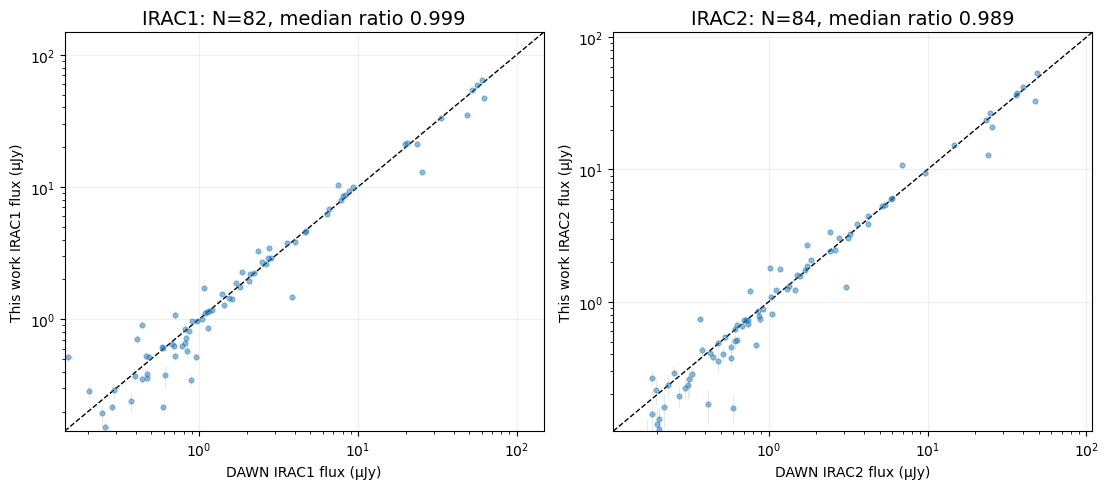

In [7]:
dawn_path = irac.fetch_dawn_pl_catalog(DAWN_FIELD, IRAC_DIR / "catalogs")
dawn = irac.read_dawn_region(dawn_path, TARGET_RA, TARGET_DEC,
                             radius_arcsec=np.sqrt(2) * SIZE_ARCSEC / 2 + 5)
comparisons = irac.compare_dawn(catalog, dawn)
ep.viz.show_dawn_comparison(comparisons)
plt.show()

*Our IRAC1 and IRAC2 fluxes against the DAWN catalog for the comparison sample.*

### Individual sources

First a galaxy that agrees with DAWN: the highest-S/N extended source in
the comparison sample whose IRAC1 flux is within 5% of DAWN. Any position
inside the field can be shown this way, and `result.image_set(band)`
returns the full images with their WCS.

ExpGalaxy: IRAC1 54.30 µJy, S/N 50, ratio to DAWN 1.036


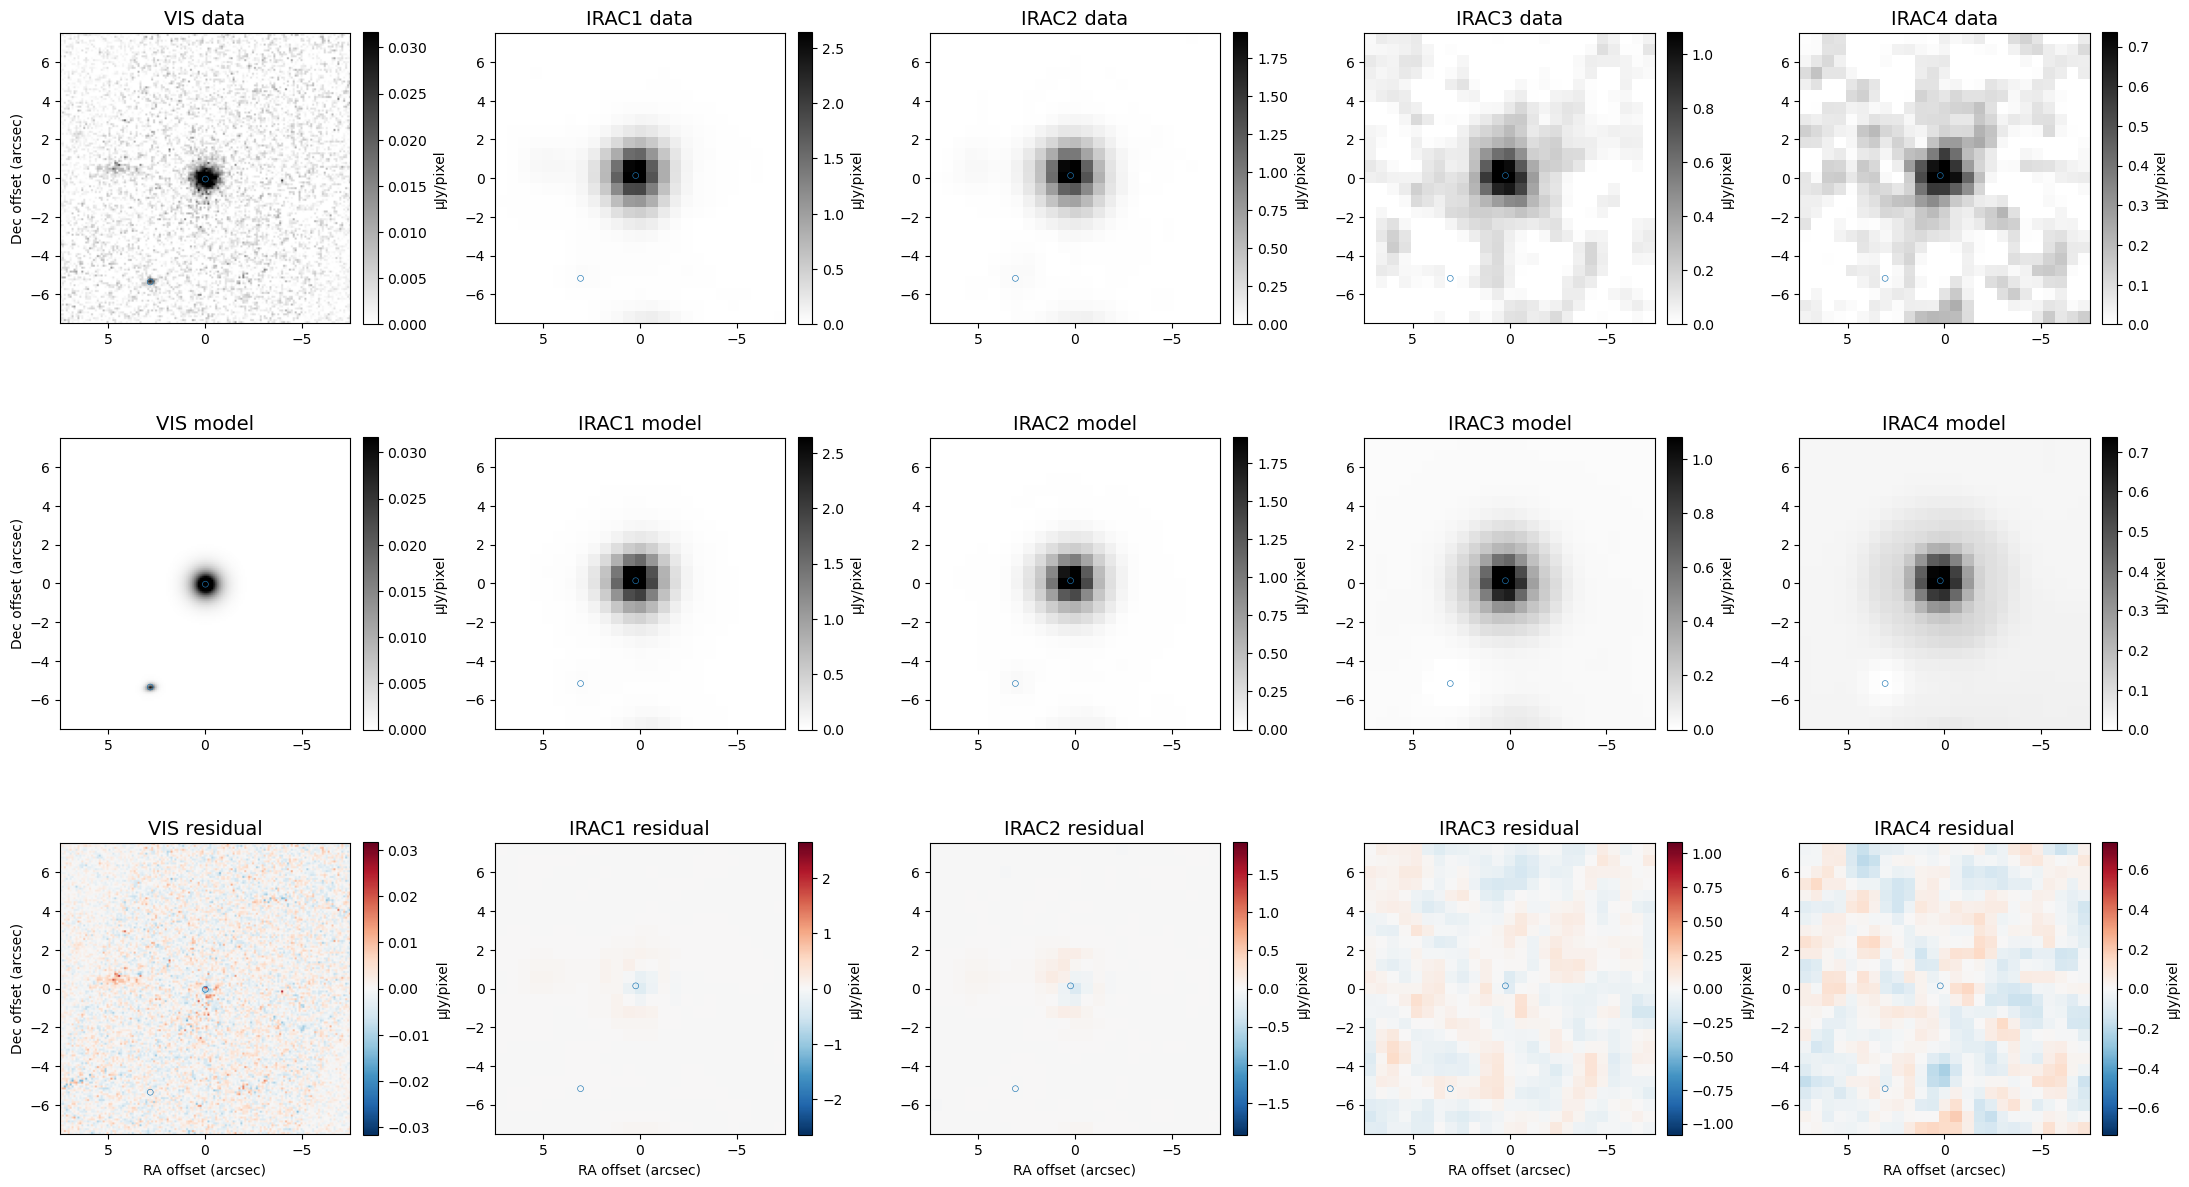

In [8]:
good = comparisons["IRAC1"]
ratio = np.asarray(good["IRAC1_over_dawn"], float)
snr = np.asarray(good["flux_IRAC1_ujy"], float) / np.asarray(good["flux_err_IRAC1_ujy"], float)
ok = (np.asarray(good["comparison_selected"]) & (np.abs(ratio - 1) < 0.05)
      & (np.asarray(good["model"]) != "PointSource"))
j = np.flatnonzero(ok)[np.argmax(snr[ok])]
print(f"{good['model'][j]}: IRAC1 {good['flux_IRAC1_ujy'][j]:.2f} µJy, "
      f"S/N {snr[j]:.0f}, ratio to DAWN {ratio[j]:.3f}")
ep.viz.show_fit(result, ("VIS", *CHANNELS), ra=float(good["ra"][j]),
                dec=float(good["dec"][j]), size_arcsec=15.0)
plt.show()

*A galaxy that agrees with DAWN: data, model, and residual in VIS and the IRAC channels.*

Now the sources that disagree most with DAWN. The table ranks the
comparison sample with S/N ≥ 5 in both catalogs by |log10(flux ratio)|.

In [9]:
targets = irac.select_dawn_disagreements(comparisons["IRAC1"], "IRAC1",
                                         minimum_snr=5.0, top_n=10)
targets

object_id,ra,dec,model,flux_IRAC1_ujy,flux_err_IRAC1_ujy,dawn_flux_IRAC1_ujy,dawn_flux_err_IRAC1_ujy,snr,dawn_snr,over_dawn,disagreement_dex,difference_sigma,nearest_source_arcsec,dawn_match_sep_arcsec
,deg,deg,,uJy,uJy,,,,,,,,,
int64,float64,float64,str20,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
-529161247280990803,52.91612466650636,-28.099082282889665,ExpGalaxy,0.5162315202028162,0.04060719411078972,0.14886453177833683,0.012170077301561832,12.712809429638689,12.232012015176968,3.4677939334232977,0.5400532825077192,8.666015152421677,9.295933073901145,0.042938594395576964
-529180952281095975,52.91809481558267,-28.109605012246394,ExpGalaxy,0.21569590164326033,0.010538311951020354,0.592718914253979,0.01320127584040165,20.467784845026905,44.89860839359187,0.36390926028528087,0.43900689291712114,-22.320009108008104,7.031984104409603,0.007118659430069023
-529293545281117804,52.92934322765411,-28.11176423683019,ExpGalaxy,1.4711135569265217,0.06302878000720426,3.832765879338333,0.015179083682596684,23.340346374439928,252.5031128020412,0.3838255722471852,0.41586609391562995,-36.42794144047993,6.684493753154539,0.06586830733252427
-529319759280967214,52.93197859317756,-28.096722329166358,ExpGalaxy,0.34782155216051236,0.03763071912177838,0.8957722152741555,0.012513959780335426,9.243021666285786,71.58183588553496,0.38829240986678726,0.4108410987281957,-13.817282166759671,6.326066371823274,0.09044588341123516
-529628065280957553,52.96281340750938,-28.095753600956353,PointSource,0.9042859172910225,0.03157800777697918,0.4343103622177937,0.016167331486940384,28.636572759040863,26.863453784480146,2.082119138657691,0.31850557617416836,13.24766945375019,6.276958118220308,0.0216467508049777
-529514347280789974,52.95142547347889,-28.07900401161318,DevGalaxy,12.921972872422304,0.26212296356984677,25.458176301126336,0.05026129260659218,49.29737057920544,506.5165454536537,0.5075765333532788,0.29449846473092833,-46.969982357732434,6.3571806119275385,0.021657991991737565
-529472493280768369,52.94725422618027,-28.076819742262987,ExpGalaxy,0.5170209954655672,0.02417546569414282,0.9568290737413382,0.012172662653028965,21.386185565427596,78.60474745870388,0.5403483335262184,0.26732618359001004,-16.248818376779443,6.26618557813885,0.031579013824604964
-529183560280865651,52.9183580192289,-28.08656560741133,DevGalaxy,0.7042813222331316,0.05070318465877103,0.405327504126751,0.008639627136290073,13.890277839013402,46.91493020852772,1.7375611451545956,0.23994009644833414,5.8123776693645235,6.4975603513587465,0.01903611414317955


The fourth-ranked source. In IRAC1 and IRAC2 the emission peaks about
1 arcsec south of the VIS source, where VIS shows nothing, and the model
stays at the VIS position, so the residual keeps that light. The fit can
only divide flux among sources in the VIS prior, and each centroid can move
by at most one IRAC pixel. An infrared source without a VIS counterpart is
therefore left in the residual, and its flux differs from DAWN, whose
source list differs. This is the morphology-prior limitation of section 8.

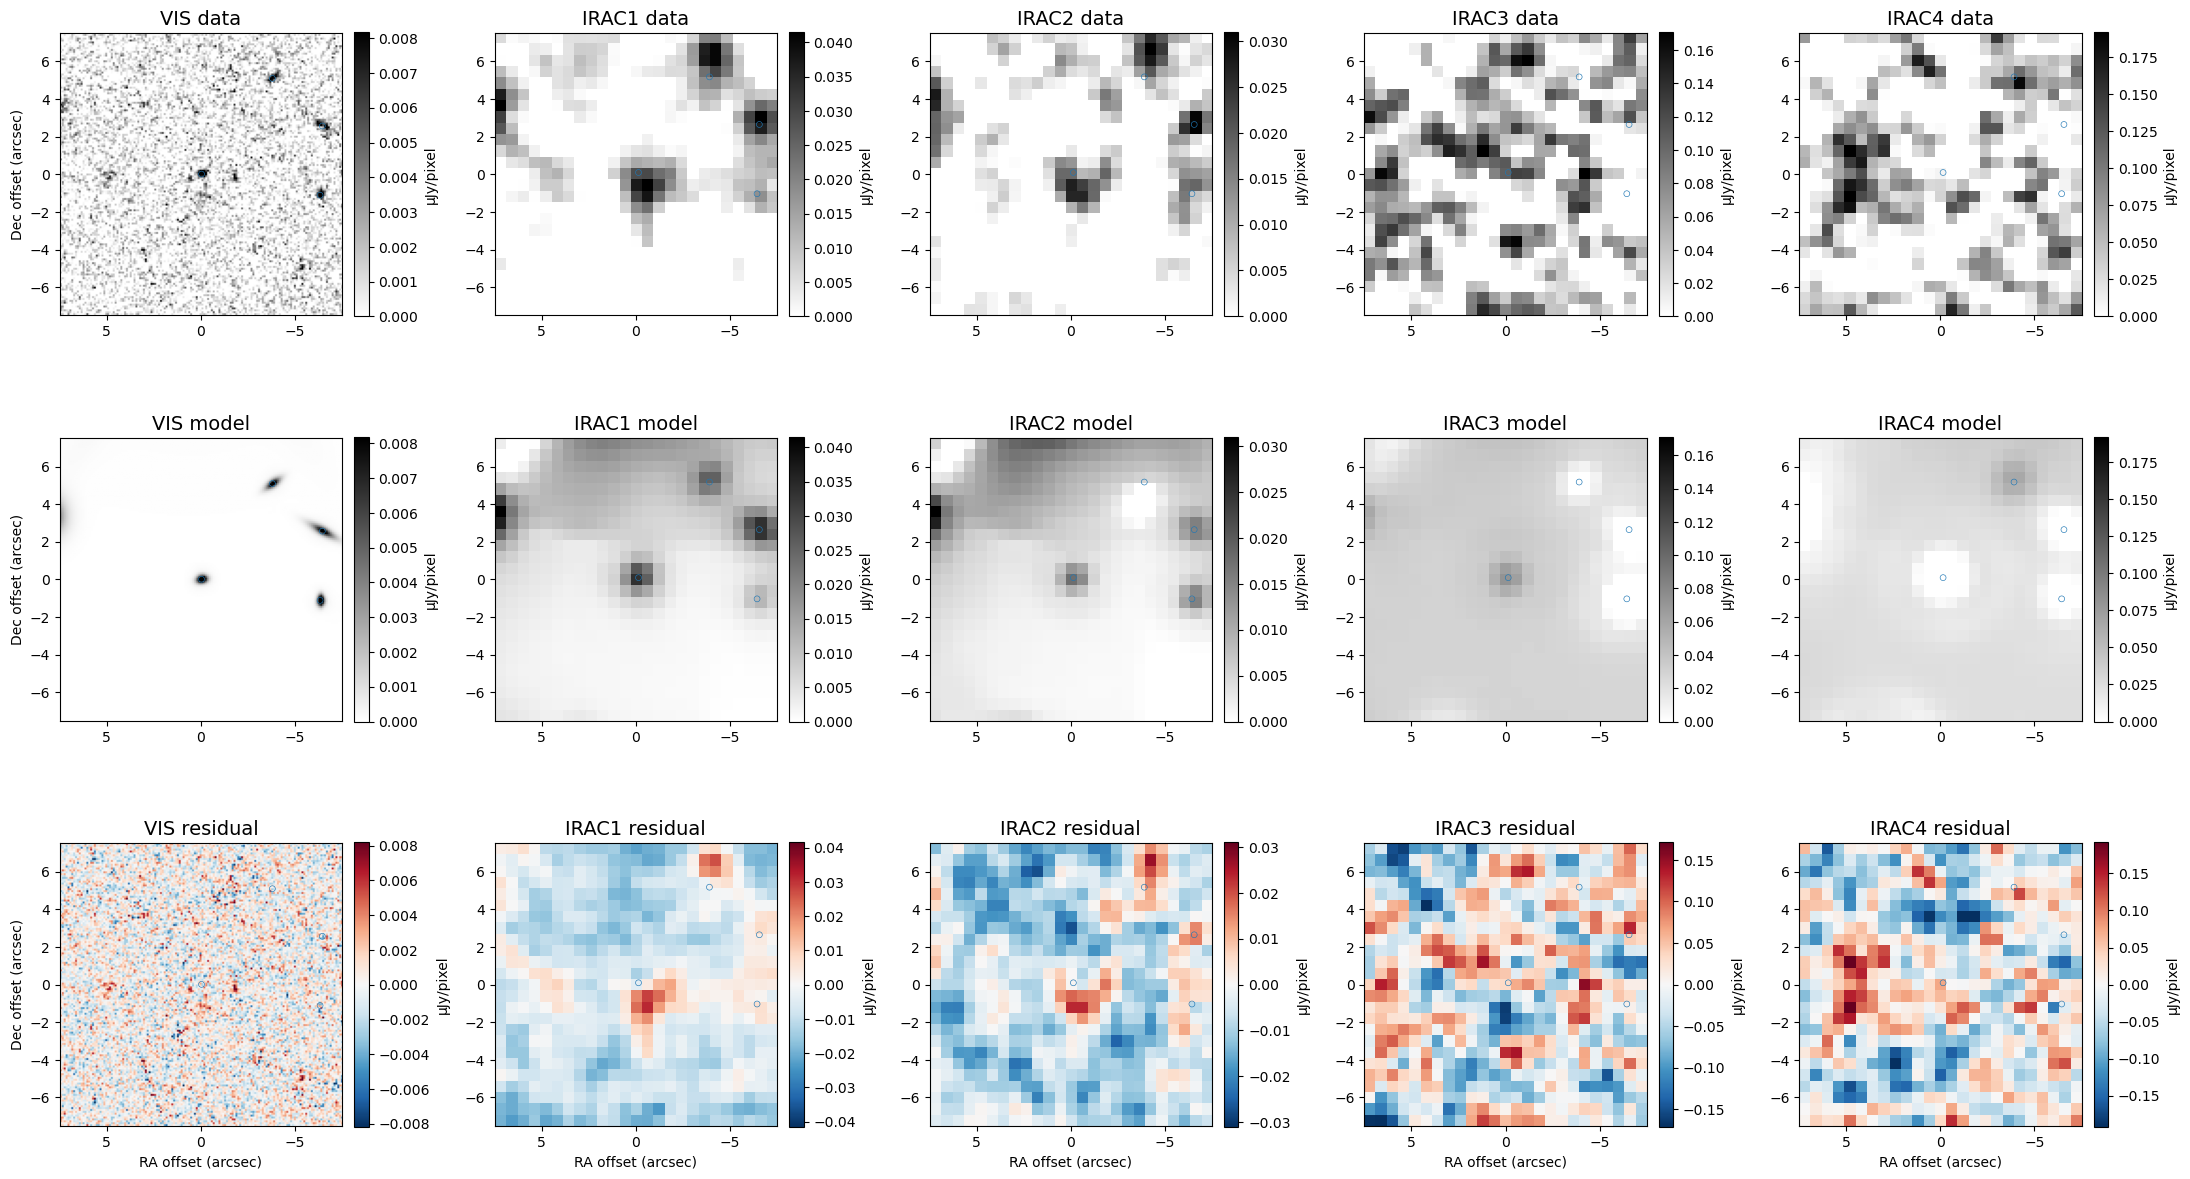

In [10]:
i = min(3, len(targets) - 1)
CUTOUT_RA, CUTOUT_DEC = float(targets["ra"][i]), float(targets["dec"][i])
ep.viz.show_fit(result, ("VIS", *CHANNELS), ra=CUTOUT_RA, dec=CUTOUT_DEC,
                size_arcsec=15.0)
plt.show()

*The fourth-ranked disagreement: the IRAC emission peaks south of the VIS position, and the
model, held at the VIS position, leaves that light in the residual.*

## 7. Comparison with unWISE

W1 (3.4 µm) and W2 (4.6 µm) lie close to IRAC1 (3.6 µm) and IRAC2
(4.5 µm), and both fits use the same VIS models. The unWISE PSF is about
6.5 arcsec wide, four times the IRAC PRF, so blended neighbours divide
their light differently in the two surveys.

All sources with positive fluxes are shown. The blue sample is selected on
IRAC alone: S/N ≥ 5 in IRAC and an IRAC flux at least five times the WISE
error. A cut on WISE S/N would keep faint sources only when WISE assigned
them extra flux, and bias the ratio high. Ringed sources also have no VIS
neighbour brighter than a third of their flux within two WISE FWHM
(13.9 arcsec), the isolation criterion of notebook 02; few pass it at
Euclid depth.

The bandpasses differ, so offsets that depend on source colour are
expected: for a Rayleigh-Jeans spectrum W1/IRAC1 is about 1.12 and
W2/IRAC2 about 0.96. The flux conventions also differ: unWISE fluxes use
the full PSF stamp, and IRAC fluxes include the Handbook correction to
infinite aperture.

The summed flux over all sources is the cleaner test of calibration,
since it does not depend on how blends are divided. Faint VIS sources next to
bright ones can receive much of their neighbours' WISE flux; they form
the cloud above the line at faint IRAC fluxes.

summed W1/IRAC1 over 856 sources: 1.027
summed W2/IRAC2 over 856 sources: 0.990


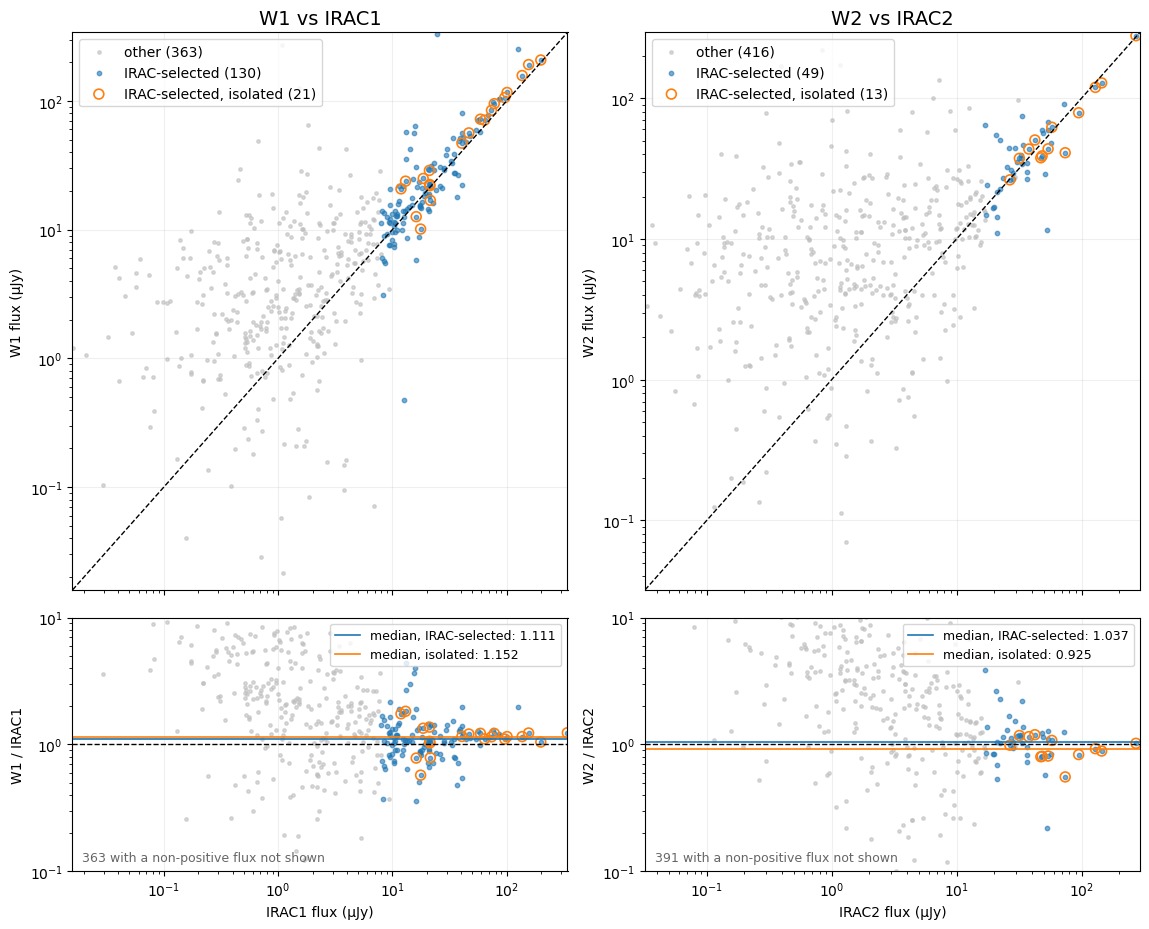

In [11]:
wise_comparisons = irac.compare_wise_irac(catalog)
for wise_band, channel in irac.WISE_IRAC_PAIRS.items():
    w = np.asarray(catalog[f"flux_{wise_band}_ujy"], float)
    c = np.asarray(catalog[f"flux_{channel}_ujy"], float)
    both = np.isfinite(w) & np.isfinite(c)
    print(f"summed {wise_band}/{channel} over {both.sum()} sources: "
          f"{w[both].sum() / c[both].sum():.3f}")
ep.viz.show_wise_irac_comparison(wise_comparisons)
plt.show()

*unWISE against IRAC flux, and their ratio, for W1 with IRAC1 and W2 with IRAC2. Blue points
are selected on IRAC alone, orange rings are VIS-isolated, and the medians use the blue sample.*

## 8. Limitations

### Effective PRF

The PRF grid is built from the detector PRFs and the exposures in each
mosaic. Each stamp is centred, resampled to the mosaic pixels and
normalized to unit sum; the Handbook core-PRF correction is then applied
to the fitted fluxes.

To test the grid, an IRAC1 fit on SEIP was repeated with only the PRF
replaced by the DAWN PRF. For 663 sources with S/N ≥ 3 in both fits, the
median flux difference was −0.08% with a scatter of 2.1%; the apparent
trend comes from the larger errors of faint sources. This scatter sets the
2% systematic included in `flux_err_<band>_ujy`.

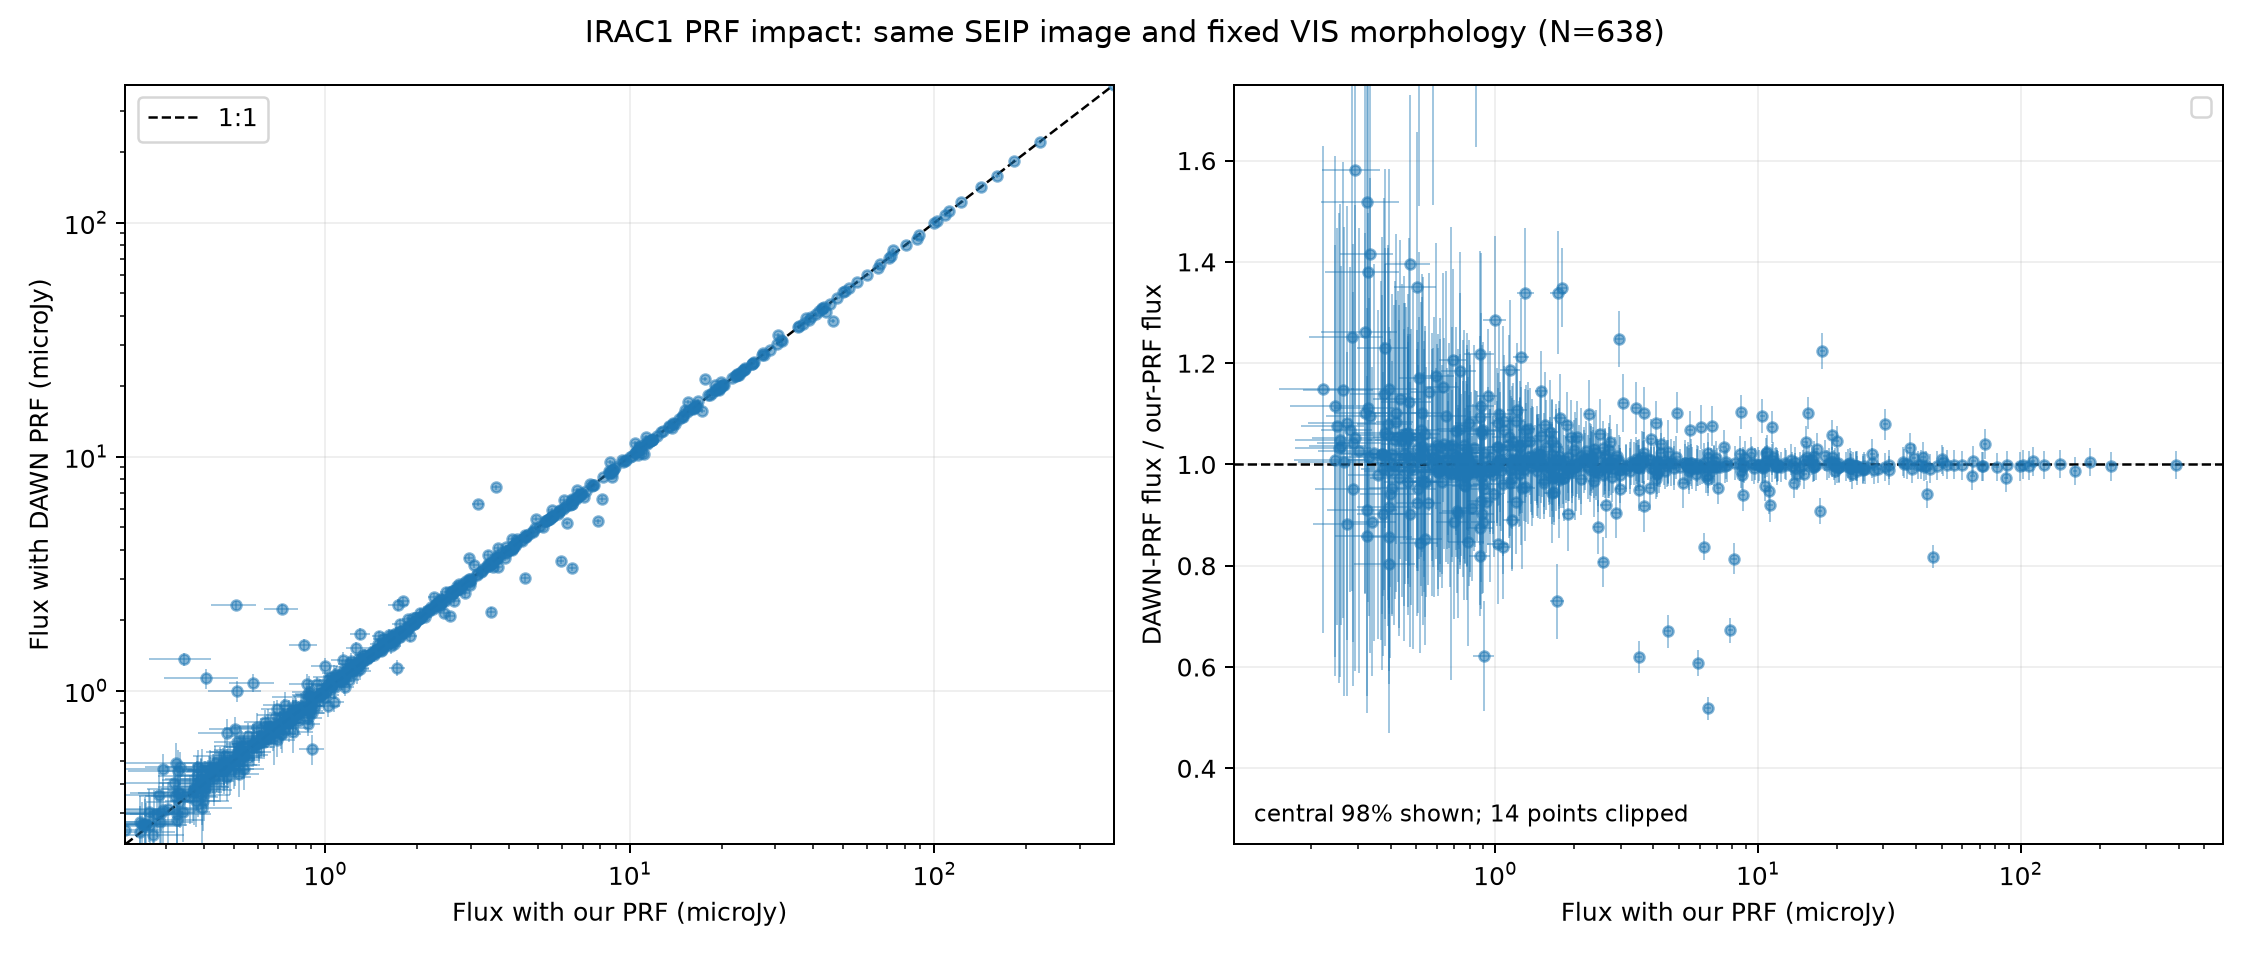

*IRAC1 fluxes fitted with the rebuilt PRF grid against the same fit with the DAWN PRF, for
sources with S/N of at least 3 in both.*

### Morphology prior

IRAC is strongly blended, so the VIS models decide how flux is divided
between neighbours. To test this, VIS was degraded to ground-based quality
(0.70 arcsec seeing, 0.168 arcsec pixels) and the models were selected
again. The median ratio to DAWN became 1.008 (N = 81) in IRAC1 and 1.025
(N = 77) in IRAC2, but individual sources scattered by about 25%. The
morphology prior moves the median by a few percent and individual fluxes
by much more.

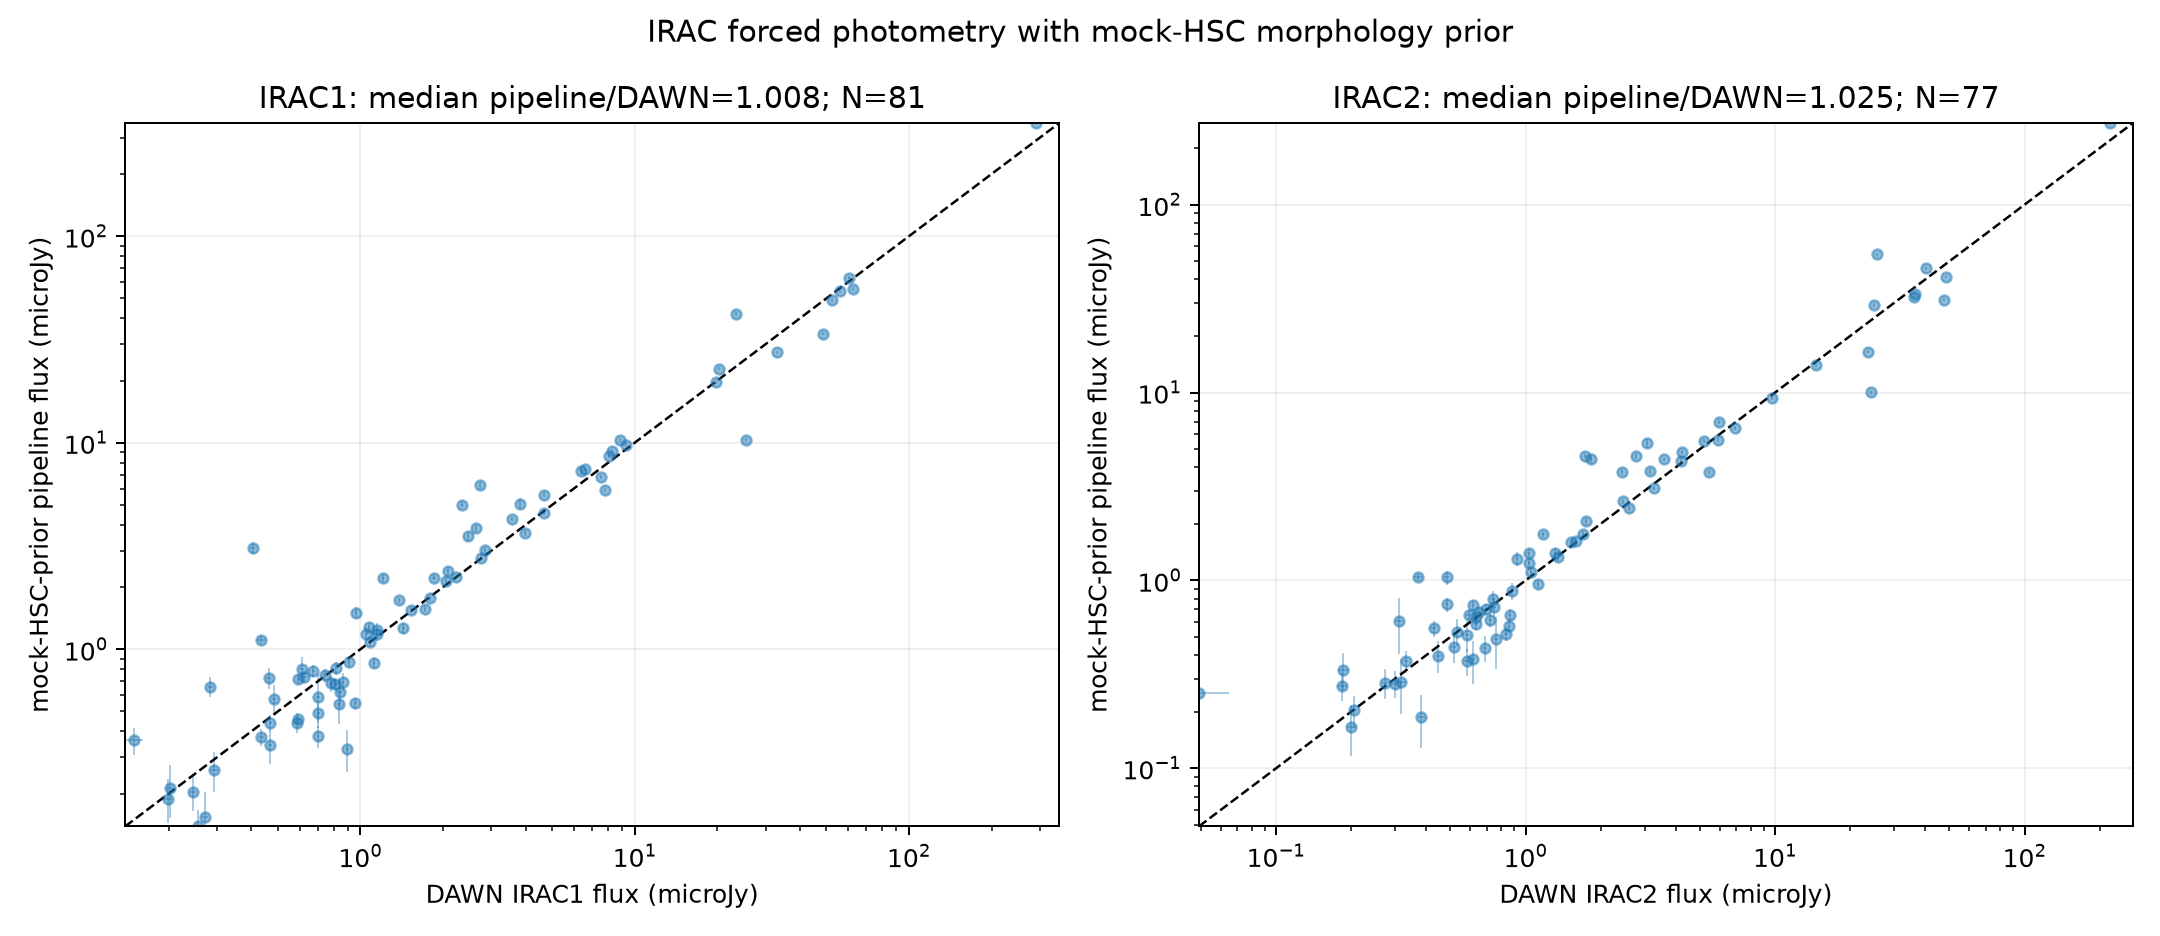

*IRAC1 and IRAC2 fluxes against DAWN with the VIS models and with models selected on VIS
degraded to ground-based quality.*